# 제5장. 양소유의 여덟 인연은 누구일까? — 누가 누구와 이어졌을까

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ITPainter/korea-china-classics-text-mining/blob/main/notebooks/ch5_network.ipynb)

『구운몽』에서 이름을 세고, 같은 줄에 함께 나온 사람을 찾아 관계도를 그린 뒤, 그 그림을 원문으로 다시 읽어 봅니다. 마지막으로 『서유기』와 『구운몽』의 호칭 변화를 나란히 놓고 비교합니다.

In [1]:
# 실습 환경 준비 (Colab에서 처음 한 번 실행)
import sys
if "google.colab" in sys.modules:
    !pip -q install "kclit @ git+https://github.com/ITPainter/korea-china-classics-text-mining.git"
from kclit.viz import setup_korean_font
print("그래프 글꼴:", setup_korean_font())

그래프 글꼴: AppleGothic


## 5.1 이름 세기

**궁금한 점:** 여덟 여인은 이야기에서 같은 무게를 가질까요? 여인들의 이름이 장마다 다르게 적혀 있어서 호칭 사전(`people.GU_GROUPS`)이 먼저 필요합니다.

In [2]:
from kclit import classics, people
gu = classics.gu()
counts = people.count_names(gu, people.GU_GROUPS)
counts.sum().sort_values(ascending=False)

양소유     561
가춘운     189
정경패     168
진채봉      83
난양공주     78
계섬월      51
적경홍      38
심요연      27
백능파      14
dtype: int64

가춘운이 가장 많이 불리고 백능파가 가장 적게 불립니다. 정경패는 12회부터 ‘英陽公主’로도 불려서(태후의 명으로 공주가 되었기 때문입니다) 호칭 사전에 함께 넣었습니다. 호칭을 합치는 규칙이 바뀌면 숫자도 바뀝니다.

## 5.2 같은 줄에 함께 나온 사람

**궁금한 점:** 누가 누구와 함께 자주 나올까요? 원문 한 줄(한 문단)을 한 단위로 보고, 같은 줄에 호칭이 함께 있으면 선으로 잇습니다.

In [3]:
from kclit import network
import matplotlib.pyplot as plt
import numpy as np
scenes = [line for c in gu for line in c.splitlines() if line.strip()]   # 원문 한 줄(한 문단)을 한 단위로 봅니다
print("줄 수:", len(scenes), "| 평균 글자 수:", round(np.mean([len(s) for s in scenes])))
g = network.character_network(scenes, people.GU_GROUPS)
network.centrality_table(g, min_weight=10)

줄 수: 1097 | 평균 글자 수: 73


,연결 중심성,매개 중심성,가중 연결
양소유,0.875,0.548,178
정경패,0.500,0.012,97
가춘운,0.375,0.000,84
난양공주,0.375,0.000,77
진채봉,0.500,0.012,74
계섬월,0.125,0.000,44
적경홍,0.125,0.000,39
심요연,0.125,0.000,30
백능파,0.000,0.000,21


**분석 단위에 주의하세요.** 여기서 ‘함께 나왔다’는 같은 **줄**에 두 사람의 호칭이 있다는 뜻입니다. 같은 장면이라는 보장은 없습니다. 이름이 가장 많이 불린 사람(가춘운)과, 다른 인물과 가장 자주 함께 나온 사람(정경패)이 다릅니다.

## 5.3 관계도 읽기

함께 나온 횟수가 10번 이상인 관계만 그림으로 그립니다.

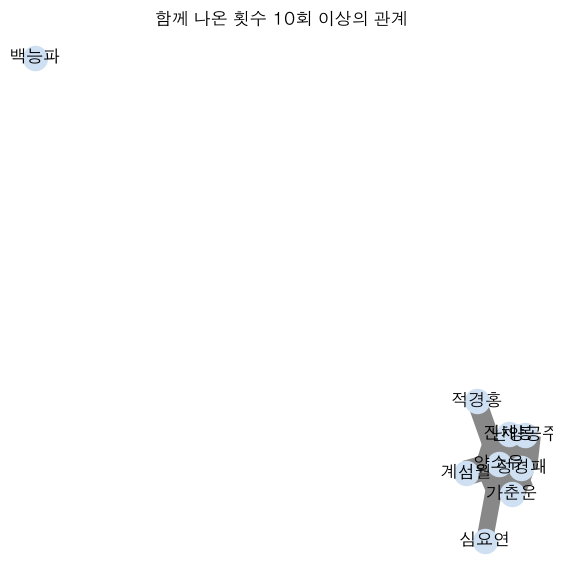

In [4]:
plt.figure(figsize=(7, 7))
network.draw(network.strong_edges(g, 10))
plt.title("함께 나온 횟수 10회 이상의 관계");

숫자가 정말 관계를 뜻하는지는 대표 줄을 직접 읽어서 확인합니다.

In [5]:
# 정경패와 가춘운이 함께 나온 줄을 읽어 봅니다
def has(line, person):
    return any(a in line for a in people.GU_GROUPS[person])
pair = [(n, line) for n, c in enumerate(gu, 1) for line in c.splitlines() if has(line, "정경패") and has(line, "가춘운")]
print("함께 나온 줄:", len(pair), "| 200자 이상인 긴 줄:", sum(len(l) >= 200 for _, l in pair))
for n, line in sorted(pair, key=lambda x: len(x[1]))[:2]:
    print(f"[{n}회]", line.strip()[:70])

함께 나온 줄: 19 | 200자 이상인 긴 줄: 6
[12회] 蘭陽曰：「英陽蛆蛆侍婢春雲，詩才亦奇矣。」
[13회] 蘭陽曰：「春云爲謁英陽姐姐，入宮屬耳。春雲亦憂丞相之疾，來候英舊。」


12회의 줄에서 난양공주가 영양공주(정경패)의 시녀 춘운을 말합니다. 두 사람이 실제로 이어진 사이라는 근거입니다. 다만 200자가 넘는 긴 줄은 두 사람이 서로 상호작용하지 않는데도 함께 묶였을 수 있으니, 이 숫자는 확정값이 아니라 ‘읽어 볼 곳’을 알려 주는 단서입니다.

## 5.4 두 작품을 나란히 놓으면

**궁금한 점:** 『서유기』와 『구운몽』에서 한 인물의 호칭은 언제, 왜 바뀔까요? 호칭 사전을 ‘계열’로 묶어 회차 구간별로 몫을 비교합니다. 같은 방법을 두 작품에 똑같이 적용합니다.

In [6]:
import pandas as pd
xiyou = classics.xiyou()
xi_groups = {"원숭이 왕 계열": ["美猴王", "猴王", "石猴"], "대성 계열": ["齊天大聖", "孫大聖", "大聖", "弼馬溫"],
             "오공 계열": ["孫悟空", "悟空"], "행자 계열": ["孫行者", "行者"], "기타": ["老孫", "猴子"]}
cx = people.count_names(xiyou, xi_groups)
early, late = cx.loc[1:7].sum(), cx.loc[14:100].sum()
pd.DataFrame({"1~7회 몫(%)": (early / early.sum() * 100).round(1), "14~100회 몫(%)": (late / late.sum() * 100).round(1),
              "1~7회 횟수": early, "14~100회 횟수": late})

,1~7회 몫(%),14~100회 몫(%),1~7회 횟수,14~100회 횟수
원숭이 왕 계열,24.6,0.9,132,61
대성 계열,36.7,17.0,197,1104
오공 계열,31.5,5.2,169,337
행자 계열,0.6,66.6,3,4314
기타,6.7,10.2,36,662


In [7]:
# 14회에서 삼장이 별명을 지어 주는 대목
i = xiyou[13].find("起個混名")
print("14회:", xiyou[13][max(0, i - 15): i + 55].replace("\n", " "))

14회: 模樣，就像那小頭陀一般，我與你起個混名，稱為行者，好麼？」悟空道：「好，好，好。」自此時又稱為孫行者。 那伯欽見孫行者一心收拾要行，卻轉身對


In [8]:
gu_groups = {"양생 계열": ["楊生", "楊少遊", "少遊"], "양상서 계열": ["楊尚書"], "승상 계열": ["楊丞相", "丞相"]}
cg = people.count_names(gu, gu_groups)
print("丞相 계열 — 1~11회:", int(cg.loc[1:11, "승상 계열"].sum()), "번 | 12~16회:", int(cg.loc[12:16, "승상 계열"].sum()), "번")
i = gu[11].find("爲大丞相")
print("12회:", gu[11][max(0, i - 12): i + 15].replace("\n", " "))
eng = people.count_names(gu, {"영양공주": ["英陽公主", "英陽"]})
print("英陽公主 호칭이 처음 나오는 회:", int(eng.index[eng["영양공주"] > 0][0]))

丞相 계열 — 1~11회: 6 번 | 12~16회: 257 번
12회: 違其懇意，下恩旨以楊步遊爲大丞相，封魏國公，食邑三萬戶
英陽公主 호칭이 처음 나오는 회: 12


두 작품에서 주인공의 호칭이 특정 회에서 한꺼번에 바뀝니다. 『서유기』는 14회에서 삼장이 ‘행자’라는 별명을 지어 준 뒤, 『구운몽』은 12회에서 양소유가 승상이 된 뒤입니다. 다만 두 작품은 언어, 분량, 장르가 달라서 ‘중국 고전은 이렇고 한국 고전은 이렇다’로 일반화할 수는 없습니다. 호칭 계열을 나눈 기준도 저자가 정했습니다.